# RNN, LSTM, and GRU: From Cell Mechanics to Time-Series Forecasting

**Goal:** understand what each recurrent architecture computes at one time step, visualize how information moves through a sequence, and compare the three architectures on the **same real time-series forecasting task**.

By the end of this notebook, you should be able to:

1. Implement a small **Vanilla RNN**, **LSTM**, and **GRU** cell calculation in Python.
2. Explain the role of hidden state, cell state, and gates.
3. Use `torch.nn.RNN`, `torch.nn.LSTM`, and `torch.nn.GRU` correctly.
4. Convert a real time series into sliding windows without random train/test leakage.
5. Train the three models under the same protocol.
6. Compare **MAE, RMSE, R², parameter count, and training time**.

> **Colab note:** CPU is sufficient. A GPU is optional. No external dataset download is required.

## 0. Academic references and dataset source

The explanations follow the original/standard literature:

- Elman, J. L. (1990). *Finding Structure in Time*. Cognitive Science. DOI: https://doi.org/10.1207/s15516709cog1402_1
- Hochreiter, S. & Schmidhuber, J. (1997). *Long Short-Term Memory*. Neural Computation. DOI: https://doi.org/10.1162/neco.1997.9.8.1735
- Cho, K. et al. (2014). *Learning Phrase Representations using RNN Encoder-Decoder for Statistical Machine Translation*. EMNLP. https://aclanthology.org/D14-1179/
- Chung, J. et al. (2014). *Empirical Evaluation of Gated Recurrent Neural Networks on Sequence Modeling*. https://arxiv.org/abs/1412.3555
- PyTorch recurrent-layer documentation: https://pytorch.org/docs/stable/nn.html#recurrent-layers

### Dataset

We use the **Mauna Loa Weekly Atmospheric CO₂** series bundled with `statsmodels`:

- approximately 2,200 weekly observations;
- historical record from 1958 to 2001 in this packaged version;
- source lineage: Keeling/Scripps and atmospheric CO₂ monitoring records;
- public-domain data.

`statsmodels` dataset documentation: https://www.statsmodels.org/stable/datasets/generated/co2.html  
NOAA current CO₂ data portal: https://gml.noaa.gov/ccgg/trends/data.html

This lab predicts the **change in CO₂ for the next week** from the previous 52 weekly changes, then reconstructs the next absolute CO₂ level in ppm.

Why predict the change rather than the raw level directly? The raw series has a strong long-term upward trend. A model can appear accurate simply by following that trend. Modeling the weekly change makes the recurrent comparison less dominated by the absolute level.

## 1. Setup

The cell below is intentionally lightweight. Google Colab normally includes these packages. If `statsmodels` is missing, the cell installs it automatically.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("statsmodels") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "statsmodels"])

import copy
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import torch
import torch.nn as nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device :", DEVICE)

PyTorch: 2.14.0+cpu
Device : cpu


# Part A — What happens inside one recurrent cell?

We will first use **scalar states**. Real networks use vectors, but scalar arithmetic makes every operation visible.

Input sequence used by all three examples:

$$x = [0.2, -0.4, 0.8, 0.1, -0.2]$$

The weights below are fixed teaching values — they are **not trained**.

In [2]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

x_sequence = np.array([0.2, -0.4, 0.8, 0.1, -0.2], dtype=np.float64)
print("Input sequence:", x_sequence)

Input sequence: [ 0.2 -0.4  0.8  0.1 -0.2]


## 2. Vanilla RNN — one recurrent state

A simple tanh RNN updates its hidden state as

$$
 h_t = \tanh(W_x x_t + W_h h_{t-1} + b).
$$

The important idea is **recurrence**: $h_t$ depends on both the current input $x_t$ and the previous hidden state $h_{t-1}$.

```text
x_t --------┐
            ├── linear combination ── tanh ──> h_t
h_(t-1) ----┘                              │
                                           └── passed to the next step
```

In [3]:
# Fixed teaching parameters
rnn_wx = 1.10
rnn_wh = 0.75
rnn_b = -0.05

h = 0.0
rnn_trace = []

for t, x_t in enumerate(x_sequence, start=1):
    pre_activation = rnn_wx * x_t + rnn_wh * h + rnn_b
    h_new = np.tanh(pre_activation)
    rnn_trace.append({
        "t": t,
        "x_t": x_t,
        "h_prev": h,
        "pre_activation": pre_activation,
        "h_t": h_new,
    })
    h = h_new

rnn_trace = pd.DataFrame(rnn_trace)
rnn_trace.round(4)

,t,x_t,h_prev,pre_activation,h_t
0,1,0.2,0.0000,0.1700,0.1684
1,2,-0.4,0.1684,-0.3637,-0.3485
2,3,0.8,-0.3485,0.5686,0.5144
3,4,0.1,0.5144,0.4458,0.4184
4,5,-0.2,0.4184,0.0438,0.0438


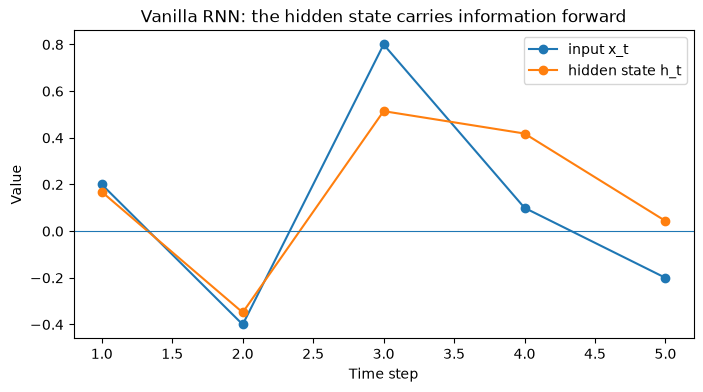

In [4]:
plt.figure(figsize=(8, 4))
plt.plot(rnn_trace["t"], rnn_trace["x_t"], marker="o", label="input x_t")
plt.plot(rnn_trace["t"], rnn_trace["h_t"], marker="o", label="hidden state h_t")
plt.axhline(0, linewidth=0.8)
plt.xlabel("Time step")
plt.ylabel("Value")
plt.title("Vanilla RNN: the hidden state carries information forward")
plt.legend()
plt.show()

### What to observe

- There is only **one recurrent state**, $h_t$.
- New information and old information are mixed by one nonlinear update.
- The model has no explicit gate saying “keep this” or “forget that”.
- Across many time steps, repeated multiplication through recurrent derivatives can make gradients shrink or grow. This is one reason long dependencies are difficult for a vanilla RNN.

## 3. LSTM — a cell state controlled by gates

A modern LSTM cell commonly uses four transformations:

$$
\begin{aligned}
f_t &= \sigma(W_f x_t + U_f h_{t-1} + b_f) \\
i_t &= \sigma(W_i x_t + U_i h_{t-1} + b_i) \\
g_t &= \tanh(W_g x_t + U_g h_{t-1} + b_g) \\
o_t &= \sigma(W_o x_t + U_o h_{t-1} + b_o) \\
c_t &= f_t c_{t-1} + i_t g_t \\
h_t &= o_t \tanh(c_t)
\end{aligned}
$$

Interpretation:

- **forget gate** $f_t$: how much previous cell state to keep;
- **input gate** $i_t$: how strongly to write the candidate;
- **candidate** $g_t$: proposed new content;
- **output gate** $o_t$: how much cell content becomes visible as $h_t$.

> Historical note: the original 1997 LSTM predates the now-common forget gate; the forget-gate extension was introduced later by Gers and colleagues.

In [5]:
# Fixed scalar teaching parameters for an LSTM.
lstm_params = {
    "f": (0.7, 0.4, 0.6),   # (W_x, U_h, bias)
    "i": (0.9, 0.2, -0.1),
    "g": (1.0, 0.5, 0.0),
    "o": (0.6, 0.3, 0.1),
}

h = 0.0
c = 0.0
lstm_trace = []

for t, x_t in enumerate(x_sequence, start=1):
    Wf, Uf, bf = lstm_params["f"]
    Wi, Ui, bi = lstm_params["i"]
    Wg, Ug, bg = lstm_params["g"]
    Wo, Uo, bo = lstm_params["o"]

    f_t = sigmoid(Wf * x_t + Uf * h + bf)
    i_t = sigmoid(Wi * x_t + Ui * h + bi)
    g_t = np.tanh(Wg * x_t + Ug * h + bg)
    o_t = sigmoid(Wo * x_t + Uo * h + bo)

    c_new = f_t * c + i_t * g_t
    h_new = o_t * np.tanh(c_new)

    lstm_trace.append({
        "t": t, "x_t": x_t,
        "f_t": f_t, "i_t": i_t, "g_t": g_t, "o_t": o_t,
        "c_prev": c, "c_t": c_new,
        "h_prev": h, "h_t": h_new,
    })
    h, c = h_new, c_new

lstm_trace = pd.DataFrame(lstm_trace)
lstm_trace.round(4)

,t,x_t,f_t,i_t,g_t,o_t,c_prev,c_t,h_prev,h_t
0,1,0.2,0.6770,0.5200,0.1974,0.5548,0.0000,0.1026,0.0000,0.0567
1,2,-0.4,0.5848,0.3897,-0.3554,0.4693,0.1026,-0.0785,0.0567,-0.0368
2,3,0.8,0.7587,0.6485,0.6536,0.6385,-0.0785,0.3644,-0.0368,0.2229
3,4,0.1,0.6812,0.5086,0.2083,0.5565,0.3644,0.3542,0.2229,0.1892
4,5,-0.2,0.6308,0.4398,-0.1050,0.5092,0.3542,0.1772,0.1892,0.0893


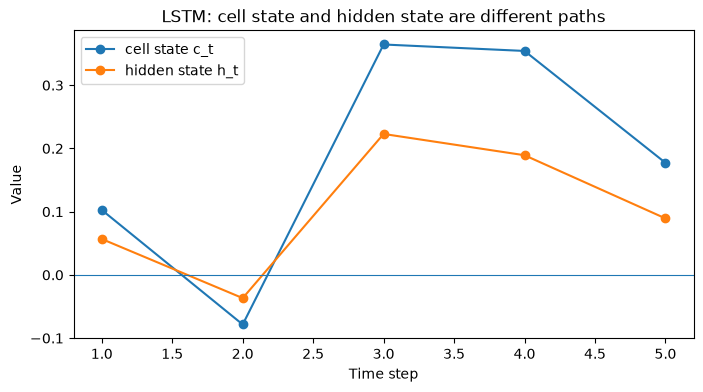

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(lstm_trace["t"], lstm_trace["c_t"], marker="o", label="cell state c_t")
plt.plot(lstm_trace["t"], lstm_trace["h_t"], marker="o", label="hidden state h_t")
plt.axhline(0, linewidth=0.8)
plt.xlabel("Time step")
plt.ylabel("Value")
plt.title("LSTM: cell state and hidden state are different paths")
plt.legend()
plt.show()

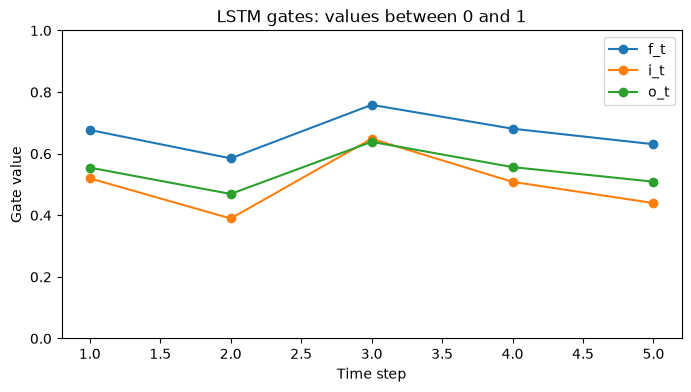

In [7]:
plt.figure(figsize=(8, 4))
for gate in ["f_t", "i_t", "o_t"]:
    plt.plot(lstm_trace["t"], lstm_trace[gate], marker="o", label=gate)
plt.ylim(0, 1)
plt.xlabel("Time step")
plt.ylabel("Gate value")
plt.title("LSTM gates: values between 0 and 1")
plt.legend()
plt.show()

### Why can LSTM preserve information better?

The cell update contains an **additive path**:

$$c_t = f_t c_{t-1} + i_t g_t.$$

When $f_t$ stays near 1, part of the old cell state can pass forward with relatively little change. This does **not** mean LSTM mathematically eliminates all vanishing-gradient problems, but it creates a much more controllable information/gradient path than a plain tanh recurrence.

## 4. GRU — gated recurrence with one state

A GRU removes the separate cell state and uses two main gates:

$$
\begin{aligned}
r_t &= \sigma(W_r x_t + U_r h_{t-1} + b_r) \\
z_t &= \sigma(W_z x_t + U_z h_{t-1} + b_z) \\
n_t &= \tanh(W_n x_t + r_t \odot (U_n h_{t-1}) + b_n) \\
h_t &= (1-z_t)n_t + z_t h_{t-1}
\end{aligned}
$$

- **reset gate** $r_t$: controls how strongly old state contributes when creating the candidate;
- **update gate** $z_t$: interpolates between old state and candidate state.

With this convention, **$z_t \approx 1$ means keep more of the old state**.

The candidate equation above follows the convention used by PyTorch. The original GRU paper uses a closely related placement of the reset operation.

In [8]:
gru_params = {
    "r": (0.8, 0.4, 0.0),
    "z": (0.5, 0.7, 0.4),
    "n": (1.0, 0.6, -0.05),
}

h = 0.0
gru_trace = []

for t, x_t in enumerate(x_sequence, start=1):
    Wr, Ur, br = gru_params["r"]
    Wz, Uz, bz = gru_params["z"]
    Wn, Un, bn = gru_params["n"]

    r_t = sigmoid(Wr * x_t + Ur * h + br)
    z_t = sigmoid(Wz * x_t + Uz * h + bz)
    n_t = np.tanh(Wn * x_t + r_t * (Un * h) + bn)
    h_new = (1.0 - z_t) * n_t + z_t * h

    gru_trace.append({
        "t": t, "x_t": x_t,
        "r_t": r_t, "z_t": z_t, "n_t": n_t,
        "h_prev": h, "h_t": h_new,
    })
    h = h_new

gru_trace = pd.DataFrame(gru_trace)
gru_trace.round(4)

,t,x_t,r_t,z_t,n_t,h_prev,h_t
0,1,0.2,0.5399,0.6225,0.1489,0.0000,0.0562
1,2,-0.4,0.4262,0.5596,-0.4100,0.0562,-0.1491
2,3,0.8,0.6411,0.6672,0.5997,-0.1491,0.1001
3,4,0.1,0.5300,0.6272,0.0816,0.1001,0.0932
4,5,-0.2,0.4694,0.5903,-0.2201,0.0932,-0.0352


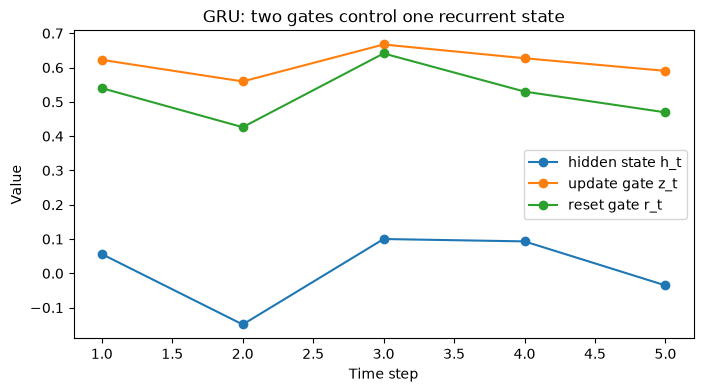

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(gru_trace["t"], gru_trace["h_t"], marker="o", label="hidden state h_t")
plt.plot(gru_trace["t"], gru_trace["z_t"], marker="o", label="update gate z_t")
plt.plot(gru_trace["t"], gru_trace["r_t"], marker="o", label="reset gate r_t")
plt.xlabel("Time step")
plt.ylabel("Value")
plt.title("GRU: two gates control one recurrent state")
plt.legend()
plt.show()

## 5. Conceptual comparison

| Property | Vanilla RNN | LSTM | GRU |
|---|---|---|---|
| Recurrent memory variables | $h_t$ | $h_t$ and $c_t$ | $h_t$ |
| Main gates | none | forget, input, output | reset, update |
| Candidate transformation | one hidden update | candidate $g_t$ | candidate $n_t$ |
| Parameters at same hidden size | lowest | highest | between RNN and LSTM |
| Long-range information control | weak/implicit | explicit | explicit |
| Typical trade-off | simplest and cheapest | most flexible gating | simpler gated alternative |

There is **no universal winner**. Architecture performance depends on the data, sequence length, optimization, hidden size, parameter budget, and task.

## 6. The same idea in PyTorch

For a batch-first input, recurrent modules expect:

```text
(batch, sequence_length, input_features)
```

`RNN` and `GRU` return `(output, h_n)`.  
`LSTM` returns `(output, (h_n, c_n))`.

In [10]:
batch_size = 2
sequence_length = 5
input_size = 1
hidden_size = 8

x_demo = torch.randn(batch_size, sequence_length, input_size)

modules = {
    "RNN": nn.RNN(input_size, hidden_size, batch_first=True),
    "LSTM": nn.LSTM(input_size, hidden_size, batch_first=True),
    "GRU": nn.GRU(input_size, hidden_size, batch_first=True),
}

for name, module in modules.items():
    output, state = module(x_demo)
    print(f"\n{name}")
    print(" output shape:", tuple(output.shape))
    if name == "LSTM":
        h_n, c_n = state
        print(" h_n shape   :", tuple(h_n.shape))
        print(" c_n shape   :", tuple(c_n.shape))
    else:
        print(" h_n shape   :", tuple(state.shape))


RNN
 output shape: (2, 5, 8)
 h_n shape   : (1, 2, 8)

LSTM
 output shape: (2, 5, 8)
 h_n shape   : (1, 2, 8)
 c_n shape   : (1, 2, 8)

GRU
 output shape: (2, 5, 8)
 h_n shape   : (1, 2, 8)


In [11]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

parameter_demo = pd.DataFrame({
    "Architecture": list(modules.keys()),
    "Recurrent parameters": [count_parameters(m) for m in modules.values()],
})
parameter_demo

,Architecture,Recurrent parameters
0,RNN,88
1,LSTM,352
2,GRU,264


At the same `input_size` and `hidden_size`, PyTorch has roughly:

- RNN: one recurrent transformation;
- GRU: three gate/candidate transformations;
- LSTM: four gate/candidate transformations.

So comparing equal hidden sizes is a **practical architecture comparison**, not a parameter-matched scientific experiment. A stricter experiment could tune hidden sizes so all models have similar parameter counts.

# Part B — Exercise: compare RNN, LSTM, and GRU on a real time series

## 7. Load the Mauna Loa weekly CO₂ dataset

The packaged dataset contains some missing weekly measurements. We first resample to a weekly grid and use time interpolation to reconstruct those historical gaps.

For a production forecasting system, missing-value handling must be chosen based on what information would actually be available at prediction time. Here the goal is an architecture lab using a fixed historical series.

In [12]:
co2_df = sm.datasets.co2.load_pandas().data.copy()
co2_df = co2_df.resample("W-SAT").mean()
missing_before = int(co2_df["co2"].isna().sum())
co2_df["co2"] = co2_df["co2"].interpolate(method="time")

print("Rows:", len(co2_df))
print("Missing values before interpolation:", missing_before)
print("Missing values after interpolation :", int(co2_df["co2"].isna().sum()))
print("Date range:", co2_df.index.min().date(), "to", co2_df.index.max().date())
co2_df.head()

Rows: 2284
Missing values before interpolation: 59
Missing values after interpolation : 0
Date range: 1958-03-29 to 2001-12-29


,co2
1958-03-29,316.1
1958-04-05,317.3
1958-04-12,317.6
1958-04-19,317.5
1958-04-26,316.4


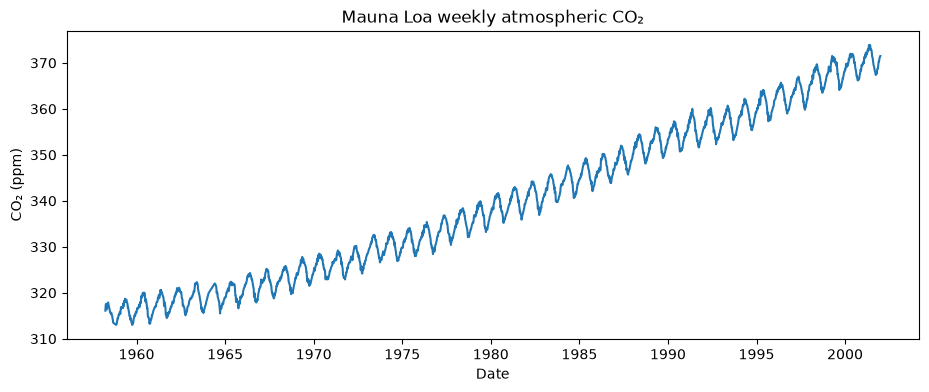

In [13]:
plt.figure(figsize=(11, 4))
plt.plot(co2_df.index, co2_df["co2"])
plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.title("Mauna Loa weekly atmospheric CO₂")
plt.show()

### Why transform the target?

The absolute CO₂ level contains a strong upward trend. We create the weekly change

$$
\Delta y_t = y_t - y_{t-1}.
$$

The learning task becomes:

> use the previous **52 weekly changes** to predict the **next weekly change**.

Then reconstruct the absolute next-week level:

$$
\hat y_{t+1} = y_t + \widehat{\Delta y}_{t+1}.
$$

This gives us two useful evaluations:

1. error on the predicted **change** — harder and more diagnostic;
2. error on the reconstructed **CO₂ level in ppm** — easier to interpret.

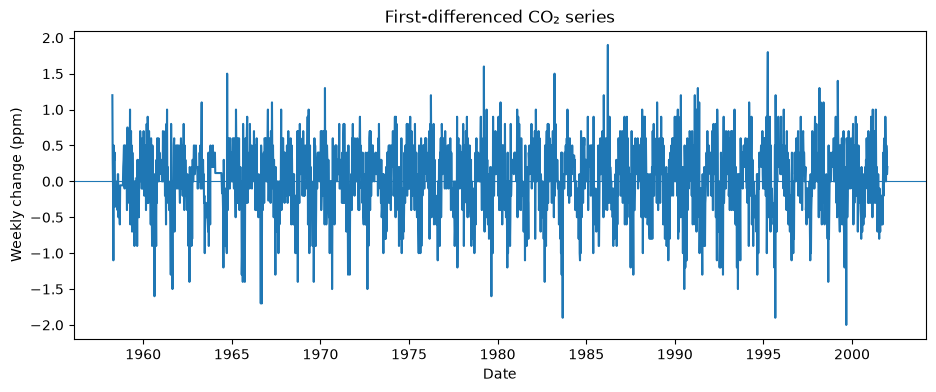

In [14]:
co2_values = co2_df["co2"].to_numpy(dtype=np.float32)
co2_changes = np.diff(co2_values).astype(np.float32)

plt.figure(figsize=(11, 4))
plt.plot(co2_df.index[1:], co2_changes)
plt.axhline(0, linewidth=0.8)
plt.xlabel("Date")
plt.ylabel("Weekly change (ppm)")
plt.title("First-differenced CO₂ series")
plt.show()

## 8. Time-aware train / validation / test split

**Do not randomly shuffle the raw time series before splitting.** That would leak future regimes into training.

We use the first 70% for training, the next 15% for validation, and the final 15% for testing.

The `StandardScaler` is fit **only on the training partition**.

In [15]:
N = len(co2_changes)
TRAIN_END = int(0.70 * N)
VAL_END = int(0.85 * N)

train_change_raw = co2_changes[:TRAIN_END]
val_change_raw = co2_changes[TRAIN_END:VAL_END]
test_change_raw = co2_changes[VAL_END:]

scaler = StandardScaler()
scaler.fit(train_change_raw.reshape(-1, 1))

train_change = scaler.transform(train_change_raw.reshape(-1, 1)).ravel().astype(np.float32)
val_change = scaler.transform(val_change_raw.reshape(-1, 1)).ravel().astype(np.float32)
test_change = scaler.transform(test_change_raw.reshape(-1, 1)).ravel().astype(np.float32)

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Weekly changes": [len(train_change), len(val_change), len(test_change)],
})
split_summary

,Split,Weekly changes
0,Train,1598
1,Validation,342
2,Test,343


## 9. Convert the sequence into sliding windows

With `SEQ_LEN = 52`, one sample is:

```text
52 past weekly changes  --->  next weekly change
[x_(t-51), ..., x_t]          x_(t+1)
```

Notice that windows are created **inside each split**, so a training window can never cross into validation or test data.

In [16]:
SEQ_LEN = 52
BATCH_SIZE = 64

class WindowDataset(Dataset):
    def __init__(self, values, seq_len):
        self.values = torch.tensor(values, dtype=torch.float32)
        self.seq_len = seq_len

    def __len__(self):
        return len(self.values) - self.seq_len

    def __getitem__(self, index):
        x = self.values[index:index + self.seq_len].unsqueeze(-1)  # (seq, feature=1)
        y = self.values[index + self.seq_len].unsqueeze(0)          # (1,)
        return x, y

train_ds = WindowDataset(train_change, SEQ_LEN)
val_ds = WindowDataset(val_change, SEQ_LEN)
test_ds = WindowDataset(test_change, SEQ_LEN)

print("Training windows  :", len(train_ds))
print("Validation windows:", len(val_ds))
print("Test windows      :", len(test_ds))

x0, y0 = train_ds[0]
print("One input shape   :", tuple(x0.shape))
print("One target shape  :", tuple(y0.shape))

Training windows  : 1546
Validation windows: 290
Test windows      : 291
One input shape   : (52, 1)
One target shape  : (1,)


In [17]:
def make_loaders(seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=generator
    )
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders()
xb, yb = next(iter(train_loader))
print("Batch x:", tuple(xb.shape), "= (batch, sequence, feature)")
print("Batch y:", tuple(yb.shape))

Batch x: (64, 52, 1) = (batch, sequence, feature)
Batch y: (64, 1)


## 10. One forecasting wrapper for all three architectures

Only the recurrent layer changes. Everything else stays the same:

```text
52-step sequence
      ↓
RNN / LSTM / GRU
      ↓
last recurrent output
      ↓
Linear(hidden_size → 1)
      ↓
predicted next weekly change
```

In [18]:
class RecurrentForecaster(nn.Module):
    def __init__(self, architecture, input_size=1, hidden_size=24):
        super().__init__()
        self.architecture = architecture.upper()

        if self.architecture == "RNN":
            self.recurrent = nn.RNN(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=1,
                nonlinearity="tanh",
                batch_first=True,
            )
        elif self.architecture == "LSTM":
            self.recurrent = nn.LSTM(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=1,
                batch_first=True,
            )
        elif self.architecture == "GRU":
            self.recurrent = nn.GRU(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=1,
                batch_first=True,
            )
        else:
            raise ValueError("architecture must be 'RNN', 'LSTM', or 'GRU'")

        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.recurrent(x)
        last_output = output[:, -1, :]
        return self.head(last_output)

for architecture in ["RNN", "LSTM", "GRU"]:
    model = RecurrentForecaster(architecture, hidden_size=24)
    print(f"{architecture:4s}: {count_parameters(model):,} trainable parameters")

RNN : 673 trainable parameters
LSTM: 2,617 trainable parameters
GRU : 1,969 trainable parameters


## 11. Training protocol

To make the comparison readable, all models use:

- hidden size = 24;
- one recurrent layer;
- Adam optimizer;
- learning rate = $10^{-3}$;
- MSE training loss;
- gradient clipping at norm 1.0;
- maximum 12 epochs;
- early stopping on validation MSE.

A single seed makes this notebook reproducible. For a paper-quality comparison, repeat the experiment over several seeds and report mean ± standard deviation.

In [19]:
HIDDEN_SIZE = 24
LEARNING_RATE = 1e-3
MAX_EPOCHS = 12
PATIENCE = 3


def evaluate_loss(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    total_items = 0
    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)
            prediction = model(x)
            loss = loss_fn(prediction, y)
            total_loss += loss.item() * len(x)
            total_items += len(x)
    return total_loss / total_items


def train_model(architecture):
    # Reset the seed so initialization is deterministic for each run.
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    train_loader, val_loader, test_loader = make_loaders()
    model = RecurrentForecaster(
        architecture=architecture,
        hidden_size=HIDDEN_SIZE,
    ).to(DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.MSELoss()

    best_val_loss = float("inf")
    best_state = None
    patience_used = 0
    history = []

    start_time = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        train_loss_sum = 0.0
        train_items = 0

        for x, y in train_loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad()
            prediction = model(x)
            loss = loss_fn(prediction, y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            train_loss_sum += loss.item() * len(x)
            train_items += len(x)

        train_loss = train_loss_sum / train_items
        val_loss = evaluate_loss(model, val_loader, loss_fn)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
        })

        if val_loss < best_val_loss - 1e-5:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            patience_used = 0
        else:
            patience_used += 1
            if patience_used >= PATIENCE:
                break

    train_seconds = time.perf_counter() - start_time
    model.load_state_dict(best_state)

    # Test predictions in standardized-change space.
    model.eval()
    pred_z = []
    target_z = []
    with torch.no_grad():
        for x, y in test_loader:
            prediction = model(x.to(DEVICE)).cpu().numpy().ravel()
            pred_z.append(prediction)
            target_z.append(y.numpy().ravel())

    pred_z = np.concatenate(pred_z)
    target_z = np.concatenate(target_z)

    # Convert weekly changes back to ppm.
    pred_change = scaler.inverse_transform(pred_z.reshape(-1, 1)).ravel()
    target_change = scaler.inverse_transform(target_z.reshape(-1, 1)).ravel()

    # A target test change at local index SEQ_LEN corresponds to global
    # change index VAL_END + SEQ_LEN. The absolute level immediately before
    # that change is co2_values[VAL_END + SEQ_LEN].
    anchors = co2_values[
        VAL_END + SEQ_LEN : VAL_END + SEQ_LEN + len(pred_change)
    ]
    pred_level = anchors + pred_change
    target_level = anchors + target_change

    metrics = {
        "Architecture": architecture,
        "Delta MAE (ppm)": mean_absolute_error(target_change, pred_change),
        "Delta RMSE (ppm)": math.sqrt(mean_squared_error(target_change, pred_change)),
        "Level MAE (ppm)": mean_absolute_error(target_level, pred_level),
        "Level RMSE (ppm)": math.sqrt(mean_squared_error(target_level, pred_level)),
        "Level R2": r2_score(target_level, pred_level),
        "Parameters": count_parameters(model),
        "Train seconds": train_seconds,
        "Epochs run": len(history),
        "Best val MSE": best_val_loss,
    }

    return {
        "model": model,
        "history": pd.DataFrame(history),
        "metrics": metrics,
        "pred_change": pred_change,
        "target_change": target_change,
        "pred_level": pred_level,
        "target_level": target_level,
    }

## 12. Train RNN, LSTM, and GRU

This is the main experiment cell. On Colab CPU it should still be lightweight; GPU is optional.

In [20]:
experiments = {}

for architecture in ["RNN", "LSTM", "GRU"]:
    print(f"Training {architecture}...")
    experiments[architecture] = train_model(architecture)
    m = experiments[architecture]["metrics"]
    print(
        f"  epochs={m['Epochs run']}, "
        f"delta_MAE={m['Delta MAE (ppm)']:.4f}, "
        f"level_RMSE={m['Level RMSE (ppm)']:.4f}, "
        f"time={m['Train seconds']:.2f}s"
    )

Training RNN...
  epochs=12, delta_MAE=0.3321, level_RMSE=0.4283, time=4.72s
Training LSTM...
  epochs=12, delta_MAE=0.3139, level_RMSE=0.4048, time=9.00s
Training GRU...
  epochs=12, delta_MAE=0.3101, level_RMSE=0.3998, time=10.98s


## 13. Add a simple persistence baseline

A useful forecast should be compared with a trivial rule.

**Persistence baseline:** next week's CO₂ level = this week's CO₂ level.  
That is equivalent to predicting the next weekly change as zero.

In [21]:
reference = experiments["RNN"]
actual_level = reference["target_level"]
actual_change = reference["target_change"]

# All architectures use exactly the same test anchors.
anchors = actual_level - actual_change
baseline_pred_level = anchors.copy()
baseline_pred_change = np.zeros_like(actual_change)

baseline_metrics = {
    "Architecture": "Persistence baseline",
    "Delta MAE (ppm)": mean_absolute_error(actual_change, baseline_pred_change),
    "Delta RMSE (ppm)": math.sqrt(mean_squared_error(actual_change, baseline_pred_change)),
    "Level MAE (ppm)": mean_absolute_error(actual_level, baseline_pred_level),
    "Level RMSE (ppm)": math.sqrt(mean_squared_error(actual_level, baseline_pred_level)),
    "Level R2": r2_score(actual_level, baseline_pred_level),
    "Parameters": 0,
    "Train seconds": 0.0,
    "Epochs run": 0,
    "Best val MSE": np.nan,
}

results = pd.DataFrame(
    [experiments[name]["metrics"] for name in ["RNN", "LSTM", "GRU"]]
    + [baseline_metrics]
)

results.round({
    "Delta MAE (ppm)": 4,
    "Delta RMSE (ppm)": 4,
    "Level MAE (ppm)": 4,
    "Level RMSE (ppm)": 4,
    "Level R2": 4,
    "Train seconds": 2,
    "Best val MSE": 4,
})

,Architecture,Delta MAE (ppm),Delta RMSE (ppm),Level MAE (ppm),Level RMSE (ppm),Level R2,Parameters,Train seconds,Epochs run,Best val MSE
0,RNN,0.3321,0.4283,0.3321,0.4283,0.9852,673,4.72,12,1.0327
1,LSTM,0.3139,0.4048,0.3139,0.4048,0.9868,2617,9.00,12,0.9504
2,GRU,0.3101,0.3998,0.3101,0.3998,0.9871,1969,10.98,12,0.9519
3,Persistence baseline,0.3948,0.4945,0.3948,0.4945,0.9803,0,0.00,0,NaN


### How to read the table

- **Delta MAE / RMSE:** direct error on the next-week change. This is the more diagnostic target for this lab.
- **Level MAE / RMSE:** error after adding the predicted change to the known current CO₂ level.
- **Level R²:** useful as an additional summary, but interpret carefully because adjacent CO₂ levels are highly autocorrelated and share a long-term trend.
- **Parameters:** model capacity/cost at the same hidden size.
- **Train seconds:** rough runtime on the current hardware; it is not a hardware-independent benchmark.

Do **not** conclude “architecture X is always best” from one small dataset and one seed.

## 14. Training curves

A healthy run usually shows training loss decreasing, while validation loss eventually stops improving. Early stopping keeps the best validation checkpoint.

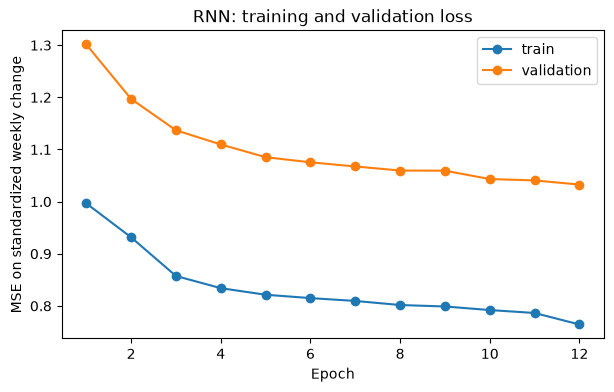

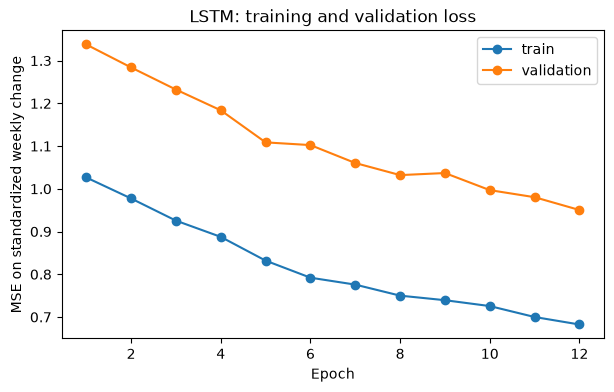

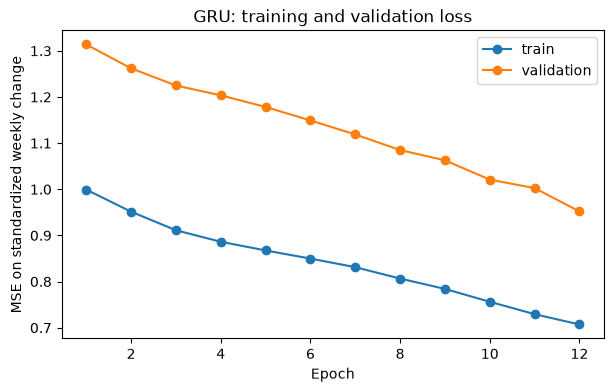

In [22]:
for architecture in ["RNN", "LSTM", "GRU"]:
    history = experiments[architecture]["history"]
    plt.figure(figsize=(7, 4))
    plt.plot(history["epoch"], history["train_loss"], marker="o", label="train")
    plt.plot(history["epoch"], history["val_loss"], marker="o", label="validation")
    plt.xlabel("Epoch")
    plt.ylabel("MSE on standardized weekly change")
    plt.title(f"{architecture}: training and validation loss")
    plt.legend()
    plt.show()

## 15. Inspect forecasts on the test period

The next three figures use the same test targets. Focus on whether a model captures the small week-to-week movements, not only the large absolute CO₂ trend.

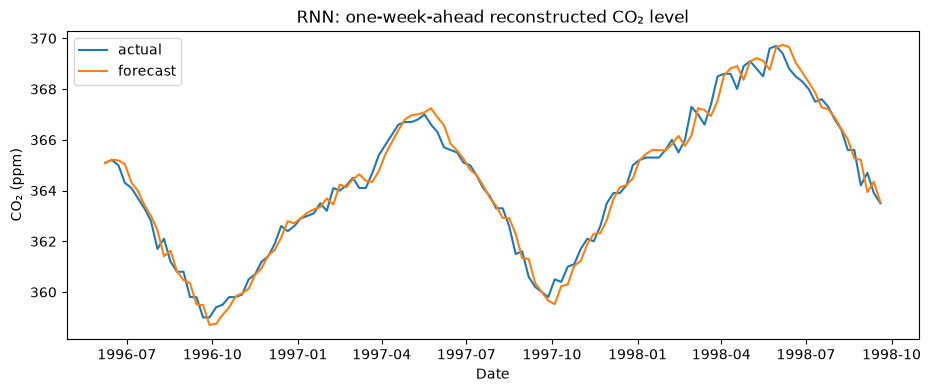

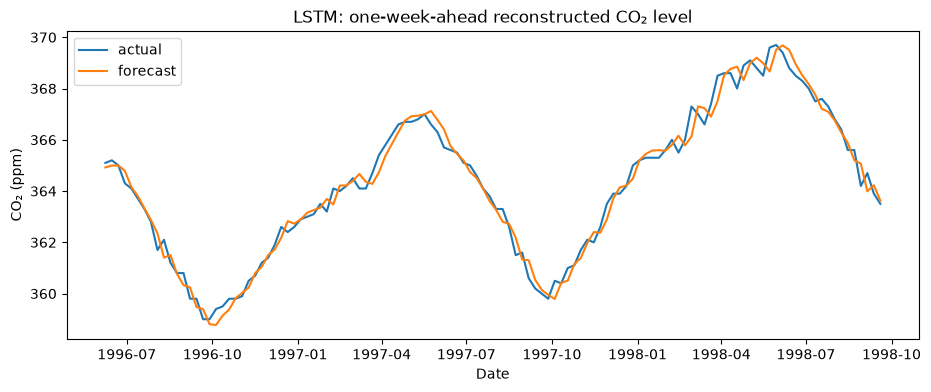

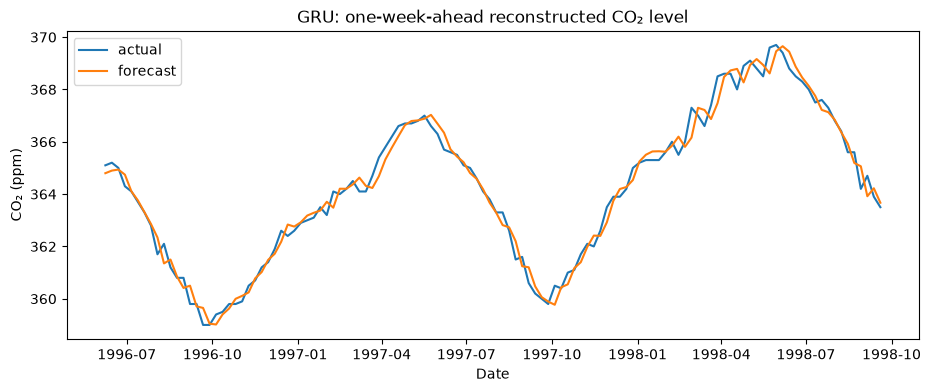

In [23]:
N_SHOW = 120

test_dates = co2_df.index[
    VAL_END + SEQ_LEN + 1 : VAL_END + SEQ_LEN + 1 + len(actual_level)
]

for architecture in ["RNN", "LSTM", "GRU"]:
    exp = experiments[architecture]
    plt.figure(figsize=(11, 4))
    plt.plot(test_dates[:N_SHOW], exp["target_level"][:N_SHOW], label="actual")
    plt.plot(test_dates[:N_SHOW], exp["pred_level"][:N_SHOW], label="forecast")
    plt.xlabel("Date")
    plt.ylabel("CO₂ (ppm)")
    plt.title(f"{architecture}: one-week-ahead reconstructed CO₂ level")
    plt.legend()
    plt.show()

## 16. Visualize the efficiency–accuracy trade-off

At equal hidden size, RNN has the fewest parameters, LSTM the most, and GRU is usually between them. The accuracy ordering is **empirical** — read it from the executed table rather than assuming it beforehand.

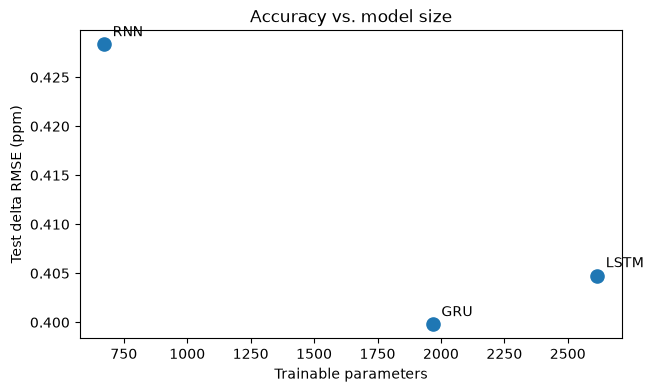

In [24]:
model_results = results[results["Architecture"].isin(["RNN", "LSTM", "GRU"])].copy()

plt.figure(figsize=(7, 4))
plt.scatter(model_results["Parameters"], model_results["Delta RMSE (ppm)"], s=90)
for _, row in model_results.iterrows():
    plt.annotate(
        row["Architecture"],
        (row["Parameters"], row["Delta RMSE (ppm)"]),
        xytext=(6, 6),
        textcoords="offset points",
    )
plt.xlabel("Trainable parameters")
plt.ylabel("Test delta RMSE (ppm)")
plt.title("Accuracy vs. model size")
plt.show()

# Part C — Interpretation and exercises

## 17. What can we conclude from this notebook?

A correct interpretation should separate **mechanism** from **this one experiment**:

### Mechanism

- Vanilla RNN has the simplest recurrent update and the smallest parameter count at equal hidden size.
- LSTM creates a separate cell state and several gates, giving it the richest explicit memory control of the three.
- GRU uses gates but keeps a single recurrent state, making it structurally simpler than LSTM.

### Experiment

Use the executed table to answer:

1. Which model obtained the smallest **Delta RMSE** in this run?
2. Did the lowest-error model also train fastest?
3. How much larger is LSTM than GRU at `hidden_size=24`?
4. Did all learned models beat the persistence baseline?
5. Does the result justify claiming one architecture is universally superior? Why not?

Remember: one dataset + one split + one seed is a **teaching experiment**, not a general benchmark.

### Trả lời câu hỏi section 17

1. **GRU** có Delta RMSE thấp nhất (0.3998 ppm), tiếp theo là LSTM (0.4048) và RNN (0.4283).
2. **Không.** GRU train chậm nhất (≈11.0 s, so với ≈9.0 s của LSTM và ≈4.7 s của RNN). Cả ba model đều chạy đủ 12 epoch, nên chênh lệch đến từ thời gian mỗi epoch chứ không phải do dừng sớm hơn. Thời gian đo được phụ thuộc vào máy và thay đổi giữa các lần chạy.
3. LSTM có **2.617** parameters, GRU có **1.969**. LSTM lớn hơn 648 parameters (≈33%), vì LSTM có 4 cổng/phép biến đổi còn GRU chỉ có 3.
4. **Có.** Cả ba đều có Delta RMSE thấp hơn persistence baseline (0.4945 ppm). GRU giảm sai số khoảng 19%.
5. **Không.** Đây chỉ là một dataset, một cách chia dữ liệu và một seed. Khoảng cách giữa GRU và LSTM chỉ 0.005 ppm, và số parameters của các model không bằng nhau. Muốn kết luận tổng quát cần chạy nhiều seed, so sánh ở cùng ngân sách parameters, và thử trên nhiều dataset (xem Exercise 2 và 3).


## 18. Student exercises

### Exercise 1 — Change memory length

Try:

```python
SEQ_LEN = 13   # about one quarter
SEQ_LEN = 26   # about half a year
SEQ_LEN = 104  # about two years
```

Recreate the datasets/loaders and rerun all models.

**Question:** Which architecture changes most when the input sequence becomes longer?

---

### Exercise 2 — Parameter-matched comparison

The current experiment uses the same hidden size, so parameter counts differ.

Find three hidden sizes such that RNN, LSTM, and GRU have approximately similar total parameter counts. Retrain them.

**Question:** Does the accuracy ranking change after controlling the parameter budget?

---

### Exercise 3 — Multiple random seeds

Run seeds such as `[0, 1, 2, 3, 4]` and report:

$$\text{mean metric} \pm \text{standard deviation}.$$

**Question:** Is the difference between LSTM and GRU larger than the run-to-run variation?

---

### Exercise 4 — Forecast more than one week

Change the task to predict 4 or 12 future weekly changes.

You will need to:

1. make each target a vector rather than a scalar;
2. change the final linear layer from `Linear(hidden_size, 1)` to `Linear(hidden_size, horizon)`;
3. reconstruct the cumulative CO₂ trajectory from predicted changes.

**Question:** Which architecture degrades most as the horizon increases?

---

### Exercise 5 — Diagnose underfitting and overfitting

Try hidden sizes `[8, 32, 128]`.

Compare:

- train loss;
- validation loss;
- test RMSE;
- parameter count;
- training time.

Explain whether each model appears to underfit, fit reasonably, or overfit.

## 19. Final checklist

Before claiming that one recurrent architecture is better, verify:

- [ ] The split respects time order.
- [ ] Scaling was fit on training data only.
- [ ] All architectures received the same input information.
- [ ] Optimization settings were controlled.
- [ ] A simple baseline was included.
- [ ] Accuracy **and** computational cost were reported.
- [ ] Multiple seeds were used for a serious comparison.
- [ ] Conclusions are limited to the tested data/task.

### Core takeaway

The progression is not simply

> RNN < LSTM < GRU

or any other fixed ranking.

A better mental model is:

> **RNN** = simplest recurrent state  
> **LSTM** = explicit gated cell-state path  
> **GRU** = gated recurrence with a more compact state design

Then use controlled experiments to decide which trade-off fits the actual problem.

In [25]:
results.round(4)

,Architecture,Delta MAE (ppm),Delta RMSE (ppm),Level MAE (ppm),Level RMSE (ppm),Level R2,Parameters,Train seconds,Epochs run,Best val MSE
0,RNN,0.3321,0.4283,0.3321,0.4283,0.9852,673,4.7186,12,1.0327
1,LSTM,0.3139,0.4048,0.3139,0.4048,0.9868,2617,9.0040,12,0.9504
2,GRU,0.3101,0.3998,0.3101,0.3998,0.9871,1969,10.9792,12,0.9519
3,Persistence baseline,0.3948,0.4945,0.3948,0.4945,0.9803,0,0.0000,0,NaN


In [26]:
baseline_results = results.copy()
baseline_results.round(4)

,Architecture,Delta MAE (ppm),Delta RMSE (ppm),Level MAE (ppm),Level RMSE (ppm),Level R2,Parameters,Train seconds,Epochs run,Best val MSE
0,RNN,0.3321,0.4283,0.3321,0.4283,0.9852,673,4.7186,12,1.0327
1,LSTM,0.3139,0.4048,0.3139,0.4048,0.9868,2617,9.0040,12,0.9504
2,GRU,0.3101,0.3998,0.3101,0.3998,0.9871,1969,10.9792,12,0.9519
3,Persistence baseline,0.3948,0.4945,0.3948,0.4945,0.9803,0,0.0000,0,NaN


In [27]:
train_ds = WindowDataset(train_change, SEQ_LEN)
val_ds = WindowDataset(val_change, SEQ_LEN)
test_ds = WindowDataset(test_change, SEQ_LEN)

In [28]:
seq_len_records = []
seq_len_experiments = {}

for current_seq_len in [13, 26, 52, 104]:
    print(f"\nSEQ_LEN = {current_seq_len}")

    SEQ_LEN = current_seq_len

    train_ds = WindowDataset(train_change, SEQ_LEN)
    val_ds = WindowDataset(val_change, SEQ_LEN)
    test_ds = WindowDataset(test_change, SEQ_LEN)

    seq_len_experiments[current_seq_len] = {}

    for architecture in ["RNN", "LSTM", "GRU"]:
        print(f"  Training {architecture}...")

        exp = train_model(architecture)
        seq_len_experiments[current_seq_len][architecture] = exp

        row = exp["metrics"].copy()
        row["SEQ_LEN"] = current_seq_len
        seq_len_records.append(row)

seq_len_results = pd.DataFrame(seq_len_records)

seq_len_results[
    [
        "SEQ_LEN",
        "Architecture",
        "Delta MAE (ppm)",
        "Delta RMSE (ppm)",
        "Parameters",
        "Train seconds",
    ]
].round(4)


SEQ_LEN = 13
  Training RNN...
  Training LSTM...
  Training GRU...

SEQ_LEN = 26
  Training RNN...
  Training LSTM...
  Training GRU...

SEQ_LEN = 52
  Training RNN...
  Training LSTM...
  Training GRU...

SEQ_LEN = 104
  Training RNN...
  Training LSTM...
  Training GRU...


,SEQ_LEN,Architecture,Delta MAE (ppm),Delta RMSE (ppm),Parameters,Train seconds
0,13,RNN,0.3230,0.4271,673,2.5048
1,13,LSTM,0.3259,0.4248,2617,3.6423
2,13,GRU,0.3251,0.4241,1969,4.1670
3,26,RNN,0.3225,0.4204,673,3.0161
4,26,LSTM,0.3153,0.4037,2617,1.4403
5,26,GRU,0.3113,0.3994,1969,2.9574
6,52,RNN,0.3321,0.4283,673,4.8659
7,52,LSTM,0.3139,0.4048,2617,8.9080
8,52,GRU,0.3101,0.3998,1969,10.7440
9,104,RNN,0.3453,0.4484,673,7.7256


In [29]:
seq_len_table = seq_len_results.pivot(
    index="SEQ_LEN",
    columns="Architecture",
    values="Delta RMSE (ppm)",
)

seq_len_table.round(4)

Architecture,GRU,LSTM,RNN
SEQ_LEN,,,
13,0.4241,0.4248,0.4271
26,0.3994,0.4037,0.4204
52,0.3998,0.4048,0.4283
104,0.4138,0.4161,0.4484


In [30]:
SEQ_LEN = 52

train_ds = WindowDataset(train_change, SEQ_LEN)
val_ds = WindowDataset(val_change, SEQ_LEN)
test_ds = WindowDataset(test_change, SEQ_LEN)

Khi thay đổi độ dài chuỗi đầu vào từ 13 đến 104 tuần, GRU đạt Delta RMSE thấp nhất ở mọi cấu hình. Kết quả tốt nhất là GRU với SEQ_LEN = 26, đạt RMSE 0.3994 ppm. Kết quả của GRU tại 52 tuần là 0.3998 ppm, chỉ cao hơn 0.0004 ppm, do đó sự khác biệt giữa 26 và 52 tuần chưa đủ lớn để đưa ra kết luận chắc chắn nếu chưa chạy nhiều random seed. Khi tăng độ dài lên 104 tuần, sai số của cả ba kiến trúc đều tăng. Điều này cho thấy cung cấp nhiều bước quá khứ hơn không nhất thiết cải thiện dự báo. RNN có khoảng dao động RMSE lớn nhất, 0.0280 ppm, và suy giảm mạnh nhất khi tăng từ 52 lên 104 tuần. Vì vậy, trong thí nghiệm này, RNN nhạy với độ dài chuỗi hơn LSTM và GRU.

### Helper for Exercises 2–5

`train_model` reads the global `HIDDEN_SIZE` and `SEED`. Also, `make_loaders(seed=SEED)` fixed its default seed when it was defined. The helper below changes these settings for a single run and then restores them, so the main experiment above is not affected.


In [31]:
def run_with_settings(architecture, hidden_size=24, seed=42):
    global HIDDEN_SIZE, SEED
    saved = (HIDDEN_SIZE, SEED, make_loaders.__defaults__)
    HIDDEN_SIZE, SEED = hidden_size, seed
    make_loaders.__defaults__ = (seed,)  # also change the shuffle order of the training data
    try:
        return train_model(architecture)
    finally:
        HIDDEN_SIZE, SEED, make_loaders.__defaults__ = saved


# Ex 2-5 use the default setup: SEQ_LEN = 52.
SEQ_LEN = 52
train_ds = WindowDataset(train_change, SEQ_LEN)
val_ds = WindowDataset(val_change, SEQ_LEN)
test_ds = WindowDataset(test_change, SEQ_LEN)


### Exercise 2 — Parameter-matched comparison

Target budget: about **2,000 parameters** (GRU with `hidden_size=24` has 1,969). For each architecture, pick the hidden size whose parameter count is closest to that budget.


In [32]:
PARAM_BUDGET = 2000

def closest_hidden_size(architecture, budget, max_hidden=128):
    return min(
        range(1, max_hidden + 1),
        key=lambda h: abs(count_parameters(RecurrentForecaster(architecture, hidden_size=h)) - budget),
    )

matched_hidden = {arch: closest_hidden_size(arch, PARAM_BUDGET) for arch in ["RNN", "LSTM", "GRU"]}
print("Hidden sizes:", matched_hidden)

matched_records = []
for architecture, hidden_size in matched_hidden.items():
    exp = run_with_settings(architecture, hidden_size=hidden_size)
    row = exp["metrics"].copy()
    row["Hidden size"] = hidden_size
    matched_records.append(row)

matched_results = pd.DataFrame(matched_records)[
    ["Architecture", "Hidden size", "Parameters", "Delta MAE (ppm)", "Delta RMSE (ppm)", "Train seconds"]
]
matched_results.round(4)


Hidden sizes: {'RNN': 43, 'LSTM': 21, 'GRU': 24}


,Architecture,Hidden size,Parameters,Delta MAE (ppm),Delta RMSE (ppm),Train seconds
0,RNN,43,2022,0.3166,0.4185,7.0497
1,LSTM,21,2038,0.3172,0.4093,7.7625
2,GRU,24,1969,0.3101,0.3998,10.8726


**Answer (Exercise 2):** Với ngân sách khoảng 2.000 parameters (RNN h=43: 2.022, LSTM h=21: 2.038, GRU h=24: 1.969), thứ hạng **không đổi**: GRU (0.3998) < LSTM (0.4093) < RNN (0.4185). Tuy vậy, khoảng cách thu hẹp lại. RNN tốt lên rõ khi được thêm parameters (0.4283 → 0.4185). LSTM kém đi một chút khi bị giảm hidden size (0.4048 → 0.4093). Như vậy, một phần lợi thế của LSTM ở thí nghiệm gốc đến từ việc nó có nhiều parameters hơn. Đây vẫn chỉ là kết quả của một seed (xem Exercise 3).


### Exercise 3 — Multiple random seeds

Each seed changes both the weight initialization and the shuffle order of the training data. Hidden size = 24, `SEQ_LEN = 52`.


In [33]:
SEEDS = [0, 1, 2, 3, 4]

seed_records = []
for seed in SEEDS:
    for architecture in ["RNN", "LSTM", "GRU"]:
        exp = run_with_settings(architecture, hidden_size=24, seed=seed)
        row = exp["metrics"].copy()
        row["Seed"] = seed
        seed_records.append(row)

seed_results = pd.DataFrame(seed_records)

seed_summary = seed_results.groupby("Architecture")[["Delta MAE (ppm)", "Delta RMSE (ppm)"]].agg(["mean", "std"])
seed_summary = seed_summary.loc[["RNN", "LSTM", "GRU"]]
display(seed_summary.round(4))

# Per-seed RMSE: shows whether the ranking stays the same across seeds.
seed_results.pivot(index="Seed", columns="Architecture", values="Delta RMSE (ppm)")[["RNN", "LSTM", "GRU"]].round(4)


Delta MAE (ppm)         Delta RMSE (ppm)        
                        mean     std             mean     std
Architecture                                                 
RNN                   0.3203  0.0031           0.4202  0.0024
LSTM                  0.3169  0.0039           0.4060  0.0051
GRU                   0.3185  0.0077           0.4114  0.0112

Architecture,RNN,LSTM,GRU
Seed,,,
0,0.4236,0.4151,0.4300
1,0.4193,0.4038,0.4093
2,0.4216,0.4035,0.4053
3,0.4180,0.4047,0.4114
4,0.4184,0.4031,0.4009


**Answer (Exercise 3):** Delta RMSE trung bình ± độ lệch chuẩn qua 5 seed: RNN **0.4202 ± 0.0024**, LSTM **0.4060 ± 0.0051**, GRU **0.4114 ± 0.0112**. Tính trung bình, LSTM tốt hơn GRU. Nghĩa là kết quả "GRU tốt nhất" ở thí nghiệm chính (seed 42) phần lớn do may mắn của seed. Chênh lệch trung bình giữa LSTM và GRU (≈0.005 ppm) **nhỏ hơn** độ dao động giữa các lần chạy của GRU (std ≈0.011), và thứ hạng LSTM/GRU đảo chiều ở seed 4. Vì vậy chưa thể kết luận kiến trúc nào tốt hơn. Chỉ có kết luận "RNN kém hơn cả hai" là ổn định: RNN đứng cuối ở 4/5 seed, và std của nó rất nhỏ.


### Exercise 4 — Forecast more than one week

- Target: a vector of the next `horizon` weekly changes.
- Head: `Linear(hidden_size, horizon)`.
- CO₂ trajectory: the last known level plus the cumulative sum of the predicted changes.

The table reports the RMSE of the **CO₂ level** at the final step of the horizon and averaged over all steps. It also includes a persistence baseline (predicts zero change, so the level stays the same).


In [34]:
class MultiStepWindowDataset(Dataset):
    def __init__(self, values, seq_len, horizon):
        self.values = torch.tensor(values, dtype=torch.float32)
        self.seq_len = seq_len
        self.horizon = horizon

    def __len__(self):
        return len(self.values) - self.seq_len - self.horizon + 1

    def __getitem__(self, index):
        x = self.values[index:index + self.seq_len].unsqueeze(-1)                      # (seq, 1)
        y = self.values[index + self.seq_len:index + self.seq_len + self.horizon]      # (horizon,)
        return x, y


def train_multi_step(architecture, horizon, hidden_size=24, seed=42):
    torch.manual_seed(seed)
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(MultiStepWindowDataset(train_change, SEQ_LEN, horizon),
                              batch_size=BATCH_SIZE, shuffle=True, generator=generator)
    val_loader = DataLoader(MultiStepWindowDataset(val_change, SEQ_LEN, horizon),
                            batch_size=BATCH_SIZE, shuffle=False)
    test_ds_h = MultiStepWindowDataset(test_change, SEQ_LEN, horizon)
    test_loader = DataLoader(test_ds_h, batch_size=BATCH_SIZE, shuffle=False)

    model = RecurrentForecaster(architecture, hidden_size=hidden_size)
    model.head = nn.Linear(hidden_size, horizon)
    model = model.to(DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.MSELoss()
    best_val_loss, best_state, patience_used = float("inf"), None, 0

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        val_loss = evaluate_loss(model, val_loader, loss_fn)
        if val_loss < best_val_loss - 1e-5:
            best_val_loss, best_state, patience_used = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            patience_used += 1
            if patience_used >= PATIENCE:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred_z = np.concatenate([model(x.to(DEVICE)).cpu().numpy() for x, _ in test_loader])
    target_z = np.concatenate([y.numpy() for _, y in test_loader])

    pred_change = scaler.inverse_transform(pred_z.reshape(-1, 1)).reshape(pred_z.shape)
    target_change = scaler.inverse_transform(target_z.reshape(-1, 1)).reshape(target_z.shape)

    # Level just before the first predicted change (same indexing as train_model).
    anchors = co2_values[VAL_END + SEQ_LEN : VAL_END + SEQ_LEN + len(test_ds_h)][:, None]
    pred_level = anchors + np.cumsum(pred_change, axis=1)
    target_level = anchors + np.cumsum(target_change, axis=1)
    return pred_level, target_level, anchors


def level_rmse(pred_level, target_level):
    return (
        math.sqrt(mean_squared_error(target_level[:, -1], pred_level[:, -1])),  # final step
        math.sqrt(mean_squared_error(target_level, pred_level)),                # all steps
    )


horizon_records = []
for horizon in [1, 4, 12]:
    for architecture in ["RNN", "LSTM", "GRU"]:
        pred_level, target_level, anchors = train_multi_step(architecture, horizon)
        final_rmse, mean_rmse = level_rmse(pred_level, target_level)
        horizon_records.append({"Horizon": horizon, "Architecture": architecture,
                                "Level RMSE final step": final_rmse, "Level RMSE all steps": mean_rmse})

    persistence_level = np.repeat(anchors, horizon, axis=1)
    final_rmse, mean_rmse = level_rmse(persistence_level, target_level)
    horizon_records.append({"Horizon": horizon, "Architecture": "Persistence",
                            "Level RMSE final step": final_rmse, "Level RMSE all steps": mean_rmse})

horizon_results = pd.DataFrame(horizon_records)
horizon_results.pivot(index="Horizon", columns="Architecture", values="Level RMSE final step")[
    ["RNN", "LSTM", "GRU", "Persistence"]
].round(4)


Architecture,RNN,LSTM,GRU,Persistence
Horizon,,,,
1,0.4169,0.4005,0.4200,0.4945
4,0.7990,0.6104,0.7808,1.2732
12,0.9565,0.8075,0.8215,3.0628


**Answer (Exercise 4):** RMSE của mức CO₂ tại bước cuối cùng tăng rõ khi horizon dài hơn: RNN 0.417 → 0.799 → 0.957, GRU 0.420 → 0.781 → 0.822, LSTM 0.401 → 0.610 → 0.808. **RNN suy giảm nhiều nhất** (tăng ≈0.54 ppm từ horizon 1 lên 12, trong khi GRU và LSTM tăng ≈0.40). LSTM giữ được ưu thế rõ nhất ở horizon 4. Sai số tăng dần vì dự báo nhiều bước phải cộng dồn các thay đổi dự báo, nên sai số cũng tích lũy theo. Cả ba model vẫn thắng xa persistence (3.06 ppm ở horizon 12), vì persistence bỏ qua xu hướng tăng của CO₂. Lưu ý: kết quả horizon 1 ở đây hơi khác bảng chính, vì head mới được khởi tạo lại và làm thay đổi chuỗi random. Đây cũng chỉ là kết quả của một seed.


### Exercise 5 — Diagnose underfitting and overfitting

`Final train loss` is the training loss in the last epoch that ran. `Best val MSE` is the lowest validation loss. Both are MSE on the standardized weekly change.


In [35]:
capacity_records = []
for hidden_size in [8, 32, 128]:
    for architecture in ["RNN", "LSTM", "GRU"]:
        exp = run_with_settings(architecture, hidden_size=hidden_size)
        history = exp["history"]
        m = exp["metrics"]
        capacity_records.append({
            "Architecture": architecture,
            "Hidden size": hidden_size,
            "Parameters": m["Parameters"],
            "Final train loss": history["train_loss"].iloc[-1],
            "Best val MSE": m["Best val MSE"],
            "Test delta RMSE (ppm)": m["Delta RMSE (ppm)"],
            "Epochs run": m["Epochs run"],
            "Best epoch": int(history["val_loss"].idxmin()) + 1,
            "Train seconds": m["Train seconds"],
        })

capacity_results = pd.DataFrame(capacity_records)
capacity_results.round(4)


,Architecture,Hidden size,Parameters,Final train loss,Best val MSE,Test delta RMSE (ppm),Epochs run,Best epoch,Train seconds
0,RNN,8,97,0.7951,1.0539,0.4386,12,12,4.6269
1,LSTM,8,361,0.8046,1.0978,0.4295,12,12,6.6316
2,GRU,8,273,0.8795,1.2051,0.4524,12,12,9.6687
3,RNN,32,1153,0.7211,0.9730,0.4173,12,11,4.7679
4,LSTM,32,4513,0.7052,0.9631,0.4053,12,12,8.8922
5,GRU,32,3393,0.7306,0.9874,0.4226,12,11,14.6785
6,RNN,128,16897,0.7615,1.0073,0.4257,8,5,7.4189
7,LSTM,128,67201,0.6893,0.9312,0.4199,12,12,5.5043
8,GRU,128,50433,0.6572,0.8844,0.3993,12,12,10.0279


**Answer (Exercise 5):**

- **Hidden size 8: underfit.** Train loss và validation loss đều cao nhất (GRU-8: train 0.88, val 1.21, test RMSE 0.452, kém nhất bảng). Model quá nhỏ để học được mẫu hình trong dữ liệu.
- **Hidden size 32: fit hợp lý.** Cả train loss lẫn validation loss đều giảm, và test RMSE tốt hơn nhiều so với size 8 với chi phí vừa phải.
- **Hidden size 128:**
  - **RNN-128 có dấu hiệu overfit hoặc mất ổn định.** Validation loss tốt nhất ở epoch 5 rồi không cải thiện nữa, nên early stopping dừng ở epoch 8. Train loss còn cao hơn RNN-32, và test RMSE kém hơn (0.426 so với 0.417).
  - **LSTM-128 và GRU-128 chưa overfit trong 12 epoch.** Validation loss vẫn giảm đến epoch cuối. GRU-128 có test RMSE tốt nhất (0.3993), nhưng dùng 50k parameters (gấp 25 lần GRU-24) chỉ để cải thiện rất ít so với hidden size 24 (0.3998).
- Ở mọi cấu hình, validation MSE (≈0.9–1.2) đều cao hơn train loss (≈0.66–0.88). Một phần nguyên nhân là chuỗi thay đổi hằng tuần rất nhiễu, và giai đoạn validation khác phân phối so với giai đoạn train.
- Thời gian train đo trên CPU rất nhiễu. Ví dụ, LSTM-128 (≈5.5 s) lại chạy nhanh hơn LSTM-32 (≈8.9 s), nên không thể kết luận từ một lần đo. Về lý thuyết, chi phí tính toán tăng theo hidden size (xấp xỉ $h^2$) và theo số cổng của kiến trúc (RNN < GRU < LSTM). Số parameters trong bảng phản ánh đúng điều này.
